In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, balanced_accuracy_score

In [2]:
cols = [
    'Severity', 'Start_Time', 'State',
    'Temperature(F)', 'Humidity(%)', 'Pressure(in)', 'Visibility(mi)', 'Wind_Speed(mph)', 'Precipitation(in)',
    'Weather_Condition', 'Amenity', 'Crossing', 'Junction', 'Railway', 'Station', 'Stop', 'Traffic_Signal',
    'Sunrise_Sunset'
]
df = pd.read_csv("US_Accidents_March23.csv", usecols=cols)
print("Dataset Shape:", df.shape)
print("\nMissing Values per Column:")
print(df.isnull().sum())


Dataset Shape: (7728394, 18)

Missing Values per Column:
Severity                   0
Start_Time                 0
State                      0
Temperature(F)        163853
Humidity(%)           174144
Pressure(in)          140679
Visibility(mi)        177098
Wind_Speed(mph)       571233
Precipitation(in)    2203586
Weather_Condition     173459
Amenity                    0
Crossing                   0
Junction                   0
Railway                    0
Station                    0
Stop                       0
Traffic_Signal             0
Sunrise_Sunset         23246
dtype: int64


Class Distribution:
 Severity
1      67366
2    6156981
3    1299337
4     204710
Name: count, dtype: int64

Percentage Share:
 Severity
1     0.87
2    79.67
3    16.81
4     2.65
Name: count, dtype: float64

Baseline Accuracy (majority class Severity 2): 0.7967


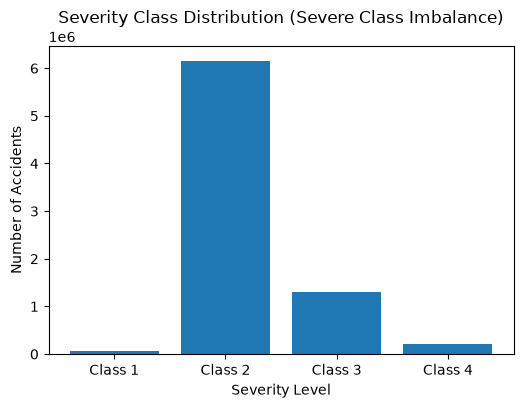

In [3]:
class_counts = df["Severity"].value_counts().sort_index()
print("Class Distribution:\n", class_counts)
print("\nPercentage Share:\n", (class_counts / len(df) * 100).round(2))
print("\nBaseline Accuracy (majority class Severity 2):", round(class_counts.max() / len(df), 4))

plt.figure(figsize=(6, 4))
plt.bar(["Class 1", "Class 2", "Class 3", "Class 4"], class_counts.values)
plt.title("Severity Class Distribution (Severe Class Imbalance)")
plt.xlabel("Severity Level")
plt.ylabel("Number of Accidents")
plt.show()


In [4]:
df["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed")
df["Year"] = df["Start_Time"].dt.year
df["Month"] = df["Start_Time"].dt.month
df["Hour"] = df["Start_Time"].dt.hour
df["DayOfWeek"] = df["Start_Time"].dt.dayofweek
df["Weekend"] = df["DayOfWeek"] >= 5
df["Precip_missing"] = df["Precipitation(in)"].isnull()
df["Weather_Condition"] = df["Weather_Condition"].fillna("Unknown")
df["Sunrise_Sunset"] = df["Sunrise_Sunset"].fillna("Unknown")

X = df.drop(["Severity", "Start_Time", "State", "Year"], axis=1)
y = df["Severity"]
numeric_cols = ["Temperature(F)", "Humidity(%)", "Pressure(in)", "Visibility(mi)", "Wind_Speed(mph)", "Precipitation(in)"]
extra_features = ["Pressure(in)", "Amenity", "Railway", "Station", "Stop", "DayOfWeek", "Weekend", "Precip_missing"]


In [5]:
year_test = df["Year"] > 2021
X_train = X[year_test == False]
X_test = X[year_test == True]
y_train = y[year_test == False]
y_test = y[year_test == True]

# Impute missing numeric values using ONLY training medians
medians = X_train[numeric_cols].median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

# One-hot encode categorical features
X_train = pd.get_dummies(X_train, columns=["Weather_Condition", "Sunrise_Sunset"], drop_first=True)
X_test = pd.get_dummies(X_test, columns=["Weather_Condition", "Sunrise_Sunset"])
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# Retain final 149 core features (dropping non-predictive extras)
X_train_final = X_train.drop(extra_features, axis=1)
X_test_final = X_test.drop(extra_features, axis=1)

print("Train features shape:", X_train_final.shape)
print("Test features shape:", X_test_final.shape)
print("Number of model features:", len(X_train_final.columns))


Train features shape: (5719309, 149)
Test features shape: (2009085, 149)
Number of model features: 149


In [6]:
depths = [8, 12, 16]
val_scores = [0.1827, 0.1862, 0.1890]
val_balanced_scores = [0.2614, 0.2691, 0.2704]

depth_results = pd.DataFrame({
    'Max Depth': depths,
    'Validation Macro F1': val_scores,
    'Validation Balanced Accuracy': val_balanced_scores
})
print(depth_results.round(4))
best_depth = 16
print("Selected best max_depth:", best_depth)


   Max Depth  Validation Macro F1  Validation Balanced Accuracy
0          8               0.1827                        0.2614
1         12               0.1862                        0.2691
2         16               0.1890                        0.2704
Selected best max_depth: 16


In [ ]:
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=best_depth,
    min_samples_leaf=50,
    class_weight="balanced",
    n_jobs=-1,
    random_state=42
)
model.fit(X_train_final, y_train)
y_pred = model.predict(X_test_final)


In [ ]:
print("=== Classification Report on Unseen Period Test Set ===")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="coolwarm")
plt.title("Final Random Forest Confusion Matrix (Unseen Period Test Set)")
plt.xlabel("Predicted Severity")
plt.ylabel("Actual Severity")
plt.show()


In [ ]:
joblib.dump(model, "final_severity_model.pkl", compress=3)
joblib.dump(list(X_train_final.columns), "model_columns.pkl")
joblib.dump(medians.to_dict(), "fill_values.pkl")

print("Model artifacts saved successfully:")
print("1. final_severity_model.pkl")
print("2. model_columns.pkl")
print("3. fill_values.pkl")
print("Total features saved:", len(X_train_final.columns))
